# 03 · Final figures: COS vs DICT vs CONTROL

Runs anywhere (numpy + matplotlib only); no model needed. Builds the per-layer comparison figures and
the animated GIF from the arrays in `data/`.

Each figure shows one layer of `Llama-3.2-3B-Instruct`:

* **Top:** head 17's attention window for all 100 generation steps, tiled left-to-right,
  top-to-bottom (step 0 top-left). All three prompts share one colour scale.
* **Bottom:** the last token's final-normed residual stream at the final generation step,
  reshaped to 24×128 and passed through a softmax **across hidden dimensions**. This is not a
  next-token distribution; it shows which residual dimensions dominate in magnitude.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))

import numpy as np
import matplotlib
import matplotlib.pyplot as plt

from attnscope import plotting, analysis

slices = {name: plotting.load_slices(ROOT / "data", name) for name in plotting.PROMPTS}
for name, s in slices.items():
    print(f"{name:8s} attn_window {s['attn_window'].shape}   last_hidden {s['last_hidden'].shape}")

ranges = plotting.global_ranges(slices)
print("attention range", ranges[0], "  hidden-softmax range", ranges[1])

cos      attn_window (100, 28, 100, 100)   last_hidden (100, 28, 3072)
dict     attn_window (100, 28, 100, 100)   last_hidden (100, 28, 3072)
control  attn_window (100, 28, 100, 100)   last_hidden (100, 28, 3072)
attention range (0.0, 0.226806640625)   hidden-softmax range (1.987314841836907e-15, 0.9998902082443237)


## One layer in detail (layer 14)

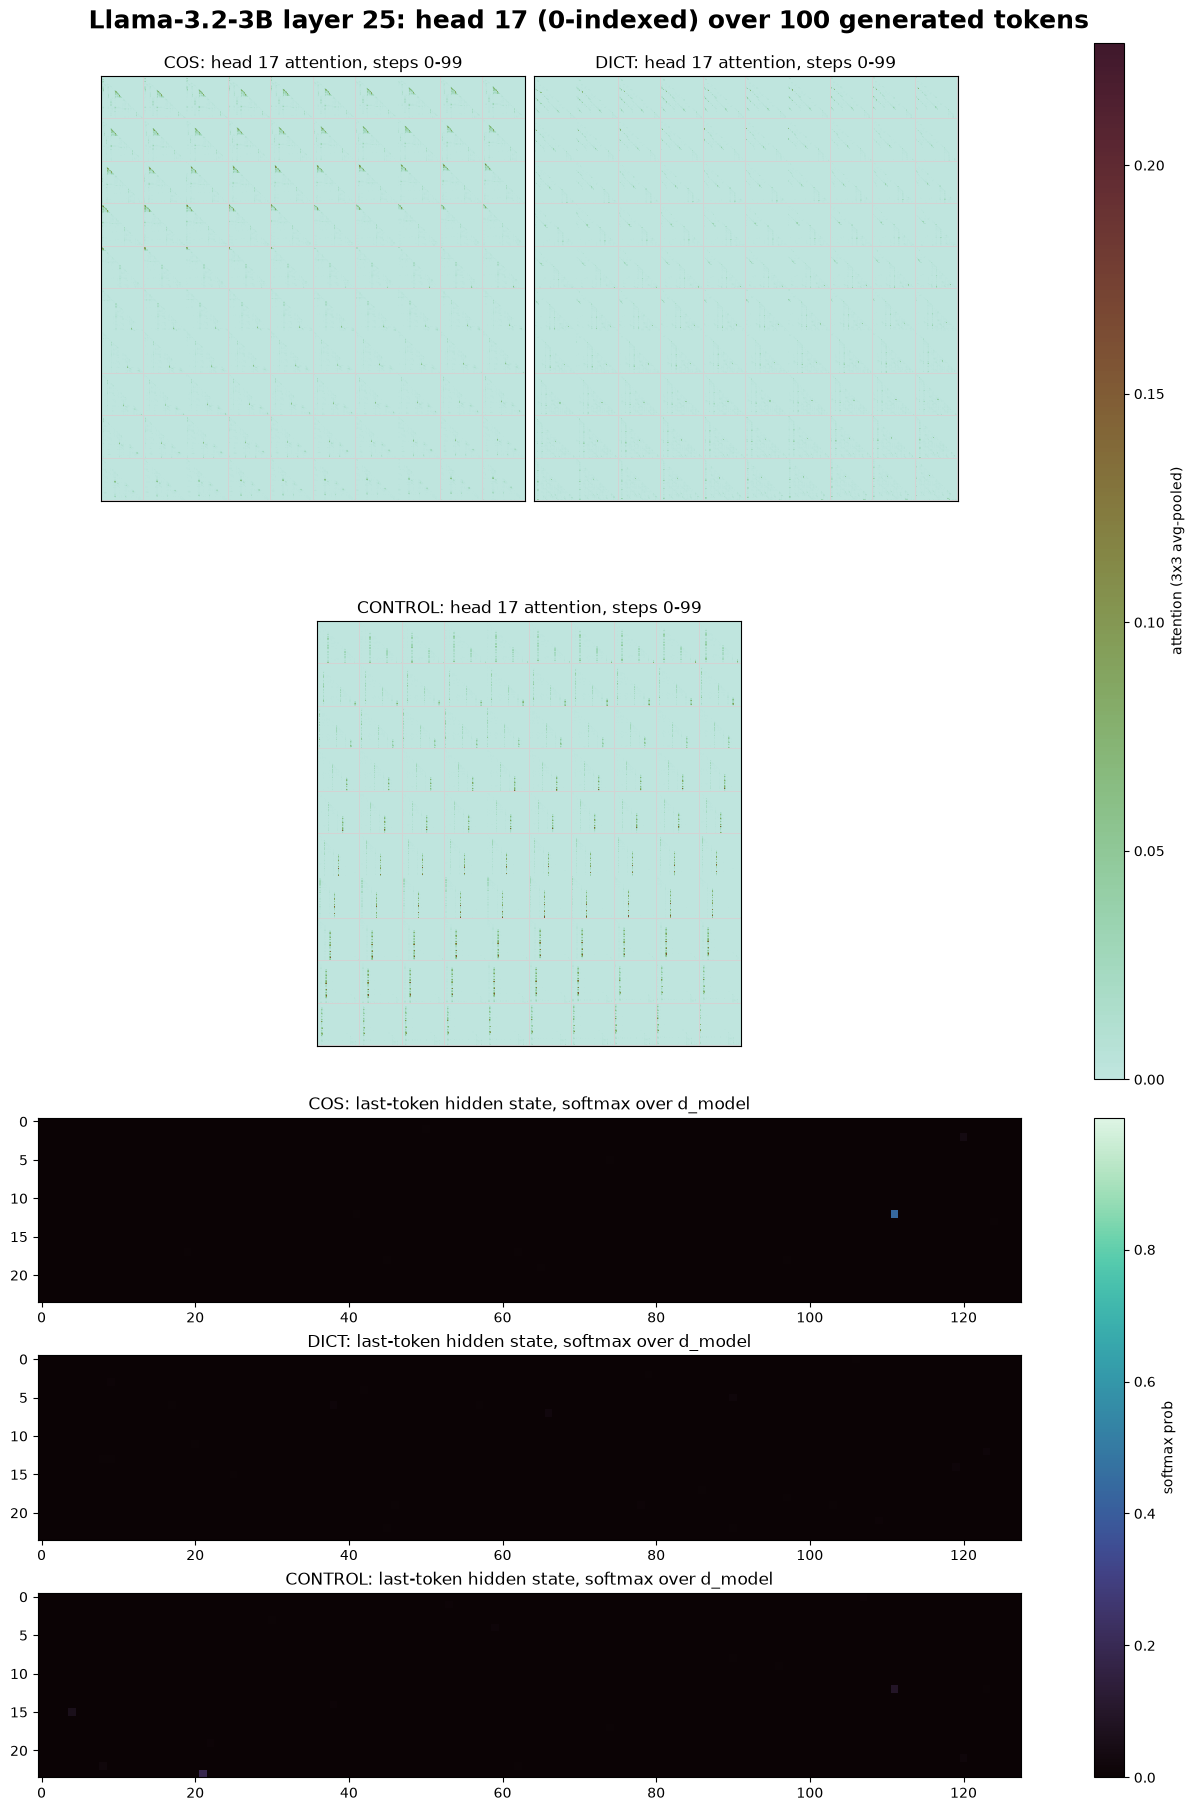

In [2]:
fig = plotting.layer_comparison_figure(slices, layer=25, ranges=ranges)
plt.show()

## Which residual dimension dominates?

The bright pixel in each bottom panel is the largest residual dimension. At the final generation step
COS's last token is dominated by dimension **962** through the middle layers, while DICT and CONTROL
mostly use **1659**. This describes a single token (the 100th generated), so treat it as a pointer
for further analysis, not a result.

In [3]:
dims = {name: analysis.dominant_dims(s["last_hidden"]) for name, s in slices.items()}
print("layer   " + "  ".join(f"{n:>8s}" for n in dims))
for layer in range(len(dims["cos"])):
    print(f"{layer:5d}   " + "  ".join(f"{dims[n][layer]:8d}" for n in dims))

layer        cos      dict   control
    0        642      2515      2250
    1        642      2515      1659
    2       3039      1673      1659
    3       3039      1659      1659
    4       3039      2273      1659
    5       3039      1659      1659
    6       3039      3039      1659
    7       3039      1659      1659
    8        859      1659      1659
    9        859      1659      1659
   10        859      1659      1659
   11       3039      1659      1659
   12       3039      1659      1659
   13       3039       962      1659
   14       3039      1659      1659
   15       3039       962      1659
   16       3039       962      2965
   17       3039      1659      2965
   18        376      1659      2965
   19        376       962      2965
   20        376       962      2965
   21        376       962      2965
   22        376       962      2965
   23        376       962      2965
   24       1647       962      2965
   25       1647       962      2965
 

## Write every layer + GIF

In [4]:
out_dir = ROOT / "figures" / "final"
paths = plotting.save_all_layers(slices, out_dir, dpi=100)
gif = plotting.make_gif(paths, out_dir / "cos_dict_control_by_layer.gif", duration_ms=1000)
print("wrote", len(paths), "figures and", gif.name)

wrote 28 figures and cos_dict_control_by_layer.gif
